# 4 · Automatic recalibration

*Roadmap:* [1 · Teleportation](01_teleportation.ipynb) → [2 · Channel noise](02_channel_noise.ipynb) → [3 · Correction from counts](03_correction_from_counts.ipynb) → **4 · Automatic recalibration** → [5 · Incoherent noise and the ceiling](05_incoherent_noise_and_ceiling.ipynb) → [6 · Correlated noise](06_correlated_noise.ipynb) → [7 · Efficient learning and tracking](07_efficient_learning_and_tracking.ipynb) → [8 · Real hardware](08_real_hardware.ipynb)

**Question.** Notebook 3 calibrated once, from zero, for one fixed channel. A real channel can be *any* rotation,
it drifts, and it jumps. Can the calibrator watch the channel, notice when the correction is no longer good, and
repair it, for every noise setting, without a human in the loop?

In [1]:
import sys
try:
    import telecorr
except ImportError:                       # running from a source checkout without installation
    sys.path.insert(0, "../src"); import telecorr

import numpy as np
import matplotlib.pyplot as plt
from telecorr import channels as C, calibrate as K, probes as Pr
from telecorr.states import MESSAGES, message_state, random_message
from telecorr.reference import number
from telecorr.rotations import NOMINAL_NOISE
from telecorr.plotting import use_style, CONDITION, INK_2
from telecorr.report import md_table, show
use_style()
MSG = [message_state(n) for n in MESSAGES]

## The model: what the cost landscape looks like

Write each leg's residual rotation W = V U (correction times noise) as a unit quaternion q = (q0, q1, q2, q3) and
let u = (q0², q1², q2², q3²) be its *squared quaternion*. The probe cost of notebook 3 is then the same bilinear form
for every channel (Proposition P4.1):

$$C = 1 - \tfrac13\, u^{(q2)\,T} M\, u^{(q3)}, \qquad M = \begin{pmatrix} 3&1&1&1\\ 1&1&0&0\\ 1&0&1&0\\ 1&0&0&1 \end{pmatrix}.$$

The channel only moves the starting point. From this form:

* **There is no spurious local minimum** (Theorem T4.2): from every point a path leads strictly downhill to C = 0.
* The other critical points are **saddles** with C ∈ {2/3, 5/6, 8/9, 1}, where a leg is turned by half a turn
  (Theorem T4.3). Near them the cost is flat. With shot noise and the poorly conditioned U(θ, φ, λ) angles, a
  single start can stall there.
* **Accept rule** (Proposition P4.10): an exact cost C < 0.01 guarantees F_avg > 0.988 and F > 0.985 for *every*
  message.

**The automatic calibrator** (`calibrate.AutoCalibrator`):

1. *monitor*: measure the mean probe P(00) with 4 000 shots per probe;
2. *detect*: if it is below 0.99, the channel has changed;
3. *recalibrate*: run a coarse COBYLA phase from several starts (the previous angles, zero, six random settings).
   Judge each start with 20 000 shots per probe, stop at the first start with cost < 0.01, refine the best one
   with the fine phases;
4. *verify*: monitor again.

## Result: arbitrary noise

The same 13 channels as the study: the "hard case" on which a single start got stuck, and 12 random channels
(any axis, angles up to π). Each calibration starts with no knowledge of the noise. Score: the worst fidelity over 10
Haar-random messages that are never used for calibration.

In [2]:
def worst_random(x, T):
    return min(K.scores(x, T, [random_message(1000 + k) for k in range(10)])["F"])

rng = np.random.default_rng(99)
cases = [("hard case", C.hard_case())] + [(f"random #{k + 1}", C.random_noise(rng)) for k in range(12)]
rows = []
for i, (name, coh) in enumerate(cases):
    T = C.leg_T(coh)
    s1 = K.ProbeSampler(T, np.random.default_rng(100 + i))
    x_single = K.cobyla(np.zeros(6), s1)
    auto = K.AutoCalibrator(K.ProbeSampler(T, np.random.default_rng(200 + i)), seed=i + 1)
    info = auto.recalibrate()
    rows.append((name, coh[2]["angle"], coh[3]["angle"], worst_random(None, T), worst_random(x_single, T),
                 worst_random(auto.params, T), len(info["starts"]), info["evaluations"]))
show(md_table(rows, ["channel", "angle q2 (rad)", "angle q3 (rad)", "no correction", "single start (notebook 3)",
                     "automatic", "starts tried", "cost evaluations"], 4))
show(f"Worst over all 13 channels: single start **{min(r[4] for r in rows):.4f}**, automatic **{min(r[5] for r in rows):.4f}** "
     f"(the study's run: {number('n0010')} and {number('n0009')}).")
stalled = [r[0] for r in rows if r[4] < 0.985]
show(f"A single start stalls below F = 0.985 on: {', '.join(stalled) if stalled else 'none'} in this run (which channels stall "
     "varies from run to run: in the study's run it was the hard case). The automatic calibrator needed one start on most channels "
     "and more where the first start stalled.")

| channel | angle q2 (rad) | angle q3 (rad) | no correction | single start (notebook 3) | automatic | starts tried | cost evaluations |
|---|---|---|---|---|---|---|---|
| hard case | 2.4659 | 1.0483 | 0.1324 | 1.0000 | 1.0000 | 3 | 445 |
| random #1 | 3.0542 | 1.7420 | 0.1011 | 0.9979 | 0.9995 | 2 | 293 |
| random #2 | 0.7725 | 1.0996 | 0.6529 | 0.9936 | 0.9998 | 2 | 302 |
| random #3 | 0.1274 | 2.7956 | 0.0670 | 0.9973 | 0.9966 | 1 | 210 |
| random #4 | 1.8822 | 0.2167 | 0.3639 | 0.9995 | 0.9992 | 1 | 183 |
| random #5 | 0.8815 | 3.0328 | 0.0659 | 0.9983 | 0.9993 | 1 | 213 |
| random #6 | 1.7991 | 2.8623 | 0.0513 | 0.9408 | 1.0000 | 2 | 299 |
| random #7 | 1.2890 | 0.4541 | 0.6236 | 0.9987 | 0.9984 | 1 | 221 |
| random #8 | 0.6852 | 1.2208 | 0.6155 | 0.9399 | 0.9990 | 4 | 487 |
| random #9 | 0.8027 | 2.6825 | 0.0908 | 0.9971 | 0.9993 | 1 | 215 |
| random #10 | 2.1294 | 1.4439 | 0.2361 | 0.9999 | 0.9999 | 1 | 232 |
| random #11 | 2.8686 | 2.2498 | 0.0859 | 1.0000 | 1.0000 | 1 | 229 |
| random #12 | 1.6199 | 1.7990 | 0.2194 | 1.0000 | 1.0000 | 1 | 216 |

Worst over all 13 channels: single start **0.9399**, automatic **0.9966** (the study's run: 0.9413 and 0.9919).

A single start stalls below F = 0.985 on: random #6, random #8 in this run (which channels stall varies from run to run: in the study's run it was the hard case). The automatic calibrator needed one start on most channels and more where the first start stalled.

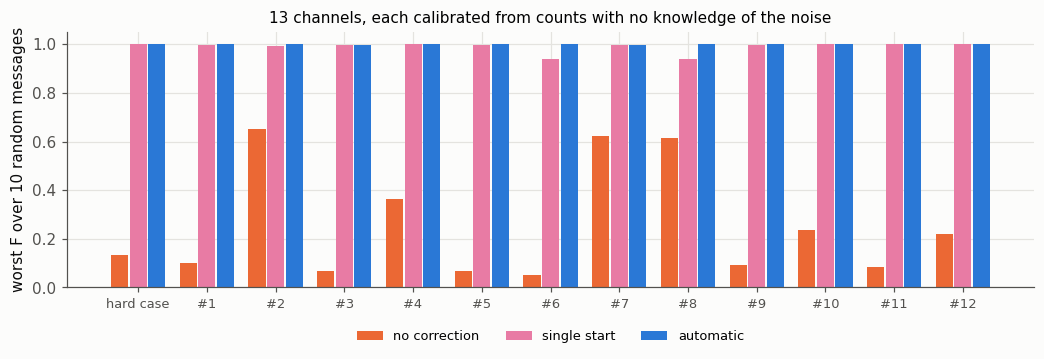

In [3]:
fig, ax = plt.subplots(figsize=(9.6, 3.4)); x = np.arange(len(rows)); w = 0.27
for k, (col, lab) in enumerate(((CONDITION["no correction"], "no correction"), (CONDITION["single start"], "single start"),
                                (CONDITION["learned from counts"], "automatic"))):
    ax.bar(x + (k - 1) * w, [r[3 + k] for r in rows], w * 0.92, color=col, label=lab)
ax.set_xticks(x, [r[0].replace("random ", "") for r in rows], fontsize=8.5); ax.set_ylim(0, 1.05)
ax.set_ylabel("worst F over 10 random messages")
ax.set_title("13 channels, each calibrated from counts with no knowledge of the noise", fontsize=10)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, fontsize=8.5); plt.tight_layout(); plt.show()

## Result: a channel that drifts and jumps

Sixty time steps of the study's timeline (same random draws): the rotations drift a little at every step
(angle ± 0.04 rad, axis ± 0.06), and at steps 20 and 40 the channel jumps to a completely new random rotation.
Three strategies: no correction, a correction calibrated once at t = 0 and then frozen, and the automatic
calibrator. Score at each step: the mean exact fidelity of the two test messages and five random ones.

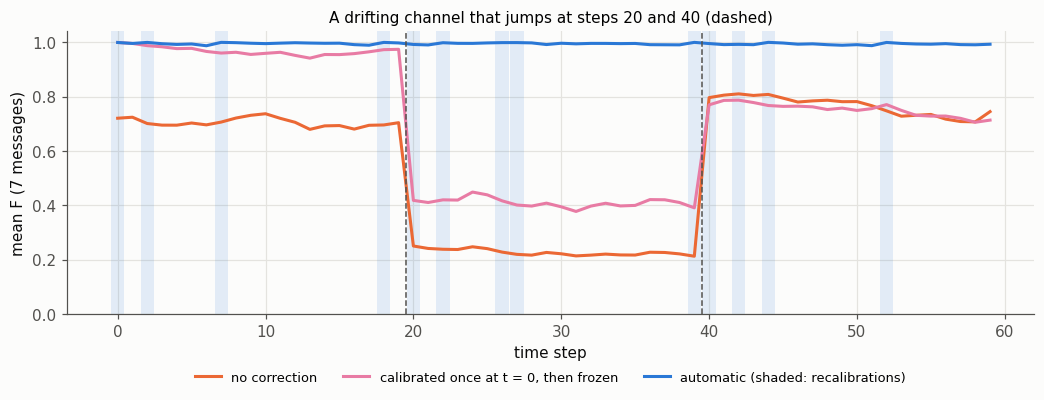

| strategy | mean F | worst F | steps with F ≥ 0.99 | recalibrations | cost evaluations |
|---|---|---|---|---|---|
| no correction | 0.5659 | 0.2125 | 0 of 60 | - | - |
| calibrated once, frozen | 0.7100 | 0.3773 | 2 of 60 | - | - |
| automatic | 0.9949 | 0.9874 | 56 of 60 | 13 | 3174 |

The study's run of the same timeline: automatic mean F 0.9955, F ≥ 0.99 in 58 of 60 steps.

In [4]:
rng = np.random.default_rng(21)
cfg = {q: dict(c) for q, c in NOMINAL_NOISE.items()}
sampler = K.ProbeSampler(C.leg_T(cfg), np.random.default_rng(4040))
auto = K.AutoCalibrator(sampler, seed=7)
tests = MSG + [random_message(2000 + k) for k in range(5)]
score = lambda x, T: float(np.mean(K.scores(x, T, tests)["F"]))           # noqa: E731
h = {k: [] for k in ("none", "frozen", "auto", "monitor", "recal", "evals")}
frozen = None
for t in range(60):
    if t in (20, 40):
        cfg = C.random_noise(rng)
    elif t > 0:
        for q in (2, 3):
            ax_ = np.asarray(cfg[q]["axis"], float); ax_ = ax_ / np.linalg.norm(ax_)
            cfg[q] = {"axis": tuple(ax_ + rng.normal(0, 0.06, 3)), "angle": float(np.clip(cfg[q]["angle"] + rng.normal(0, 0.04), 0, np.pi))}
    sampler.T = C.leg_T(cfg)
    e = auto.step()
    frozen = auto.params.copy() if frozen is None else frozen
    h["none"].append(score(None, sampler.T)); h["frozen"].append(score(frozen, sampler.T)); h["auto"].append(score(auto.params, sampler.T))
    h["monitor"].append(e["p00_before"]); h["recal"].append(e["recalibrated"]); h["evals"].append(e.get("evaluations", 0))

t = np.arange(60)
fig, ax = plt.subplots(figsize=(9.6, 3.8))
for k in np.where(h["recal"])[0]:
    ax.axvspan(k - 0.45, k + 0.45, color=CONDITION["learned from counts"], alpha=0.12, lw=0)
ax.plot(t, h["none"], color=CONDITION["no correction"], label="no correction")
ax.plot(t, h["frozen"], color=CONDITION["single start"], label="calibrated once at t = 0, then frozen")
ax.plot(t, h["auto"], color=CONDITION["learned from counts"], label="automatic (shaded: recalibrations)")
for j in (20, 40):
    ax.axvline(j - 0.5, color=INK_2, ls="--", lw=1)
ax.set_xlabel("time step"); ax.set_ylabel("mean F (7 messages)"); ax.set_ylim(0, 1.04)
ax.set_title("A drifting channel that jumps at steps 20 and 40 (dashed)", fontsize=10)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3, fontsize=8.5); plt.tight_layout(); plt.show()
rows = []
for lab, k in (("no correction", "none"), ("calibrated once, frozen", "frozen"), ("automatic", "auto")):
    f = np.array(h[k])
    rows.append((lab, f.mean(), f.min(), f"{int((f >= 0.99).sum())} of 60", sum(h["recal"]) if k == "auto" else "-",
                 sum(h["evals"]) if k == "auto" else "-"))
show(md_table(rows, ["strategy", "mean F", "worst F", "steps with F ≥ 0.99", "recalibrations", "cost evaluations"], 4))
show(f"The study's run of the same timeline: automatic mean F {number('n0015')}, F ≥ 0.99 in {number('n0016')} steps.")

## What it means

* With a multi-start search and the accept rule, the counts-only calibration recovers **every** channel tried,
  while a single start stalls on some of them.
* The monitor turns calibration into a service: it measures a few thousand shots per step, and recalibrates only
  when the channel has changed (slow drift or a sudden jump), keeping F ≥ 0.99 almost all the time. A frozen
  correction is useless after the first jump.
* The landscape explains why this works: the cost has no false minima, only saddles, which a few random starts escape.

**Next (notebook 5):** all noise so far was a rotation, so F = 1 was reachable. Real noise also has an incoherent
part (energy loss, dephasing). What is then the best possible fidelity, and does the calibrator still reach it?